# What Does a Forecast Need to Know?
## Black Week forecasting with regressors

**The client:** an online shop selling consumer electronics.

**The question:** how many units of each product will we sell during Black Week 2026 (23–30 November)?

**The idea of this notebook:** a forecast is only as good as the information it gets. We start with a model that only knows past sales, then give it one extra piece of information at a time, and measure how much each piece helps.

These extra pieces of information are called **regressors**.

*All data is synthetic. The shop and its products are fictional.*

### What is a regressor?

A regressor is **extra information that helps explain sales**, besides the sales history itself.

One rule is important: **we must know it in advance.** When we make the forecast in October, we can only use information we already have for November.

| Example | Known in advance? | Usable? |
|---|---|---|
| Black Week dates | Yes, it's in the marketing calendar | ✅ |
| Planned discount | Yes, marketing decides it weeks before | ✅ |
| Weather on Black Friday | No | ❌ |
| Competitor prices | No | ❌ |

In Prophet, there are two kinds of regressors:
- **Events:** special dates, like Black Week. Prophet learns how much each day of the event changes sales.
- **Numbers:** a value for every day, like the discount. Prophet learns how much sales change when the number changes.

### Contents
1. Load the data
2. Explore the data
3. Two traps in the data
4. Choose the products
5. Prepare the regressors
6. The test: what is each regressor worth?
7. The decision
8. Forecast Black Week 2026
9. The deliverable for the client
10. Limitations

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet

import logging
logging.getLogger("cmdstanpy").disabled = True   # hides Prophet's technical messages
logging.getLogger("prophet").disabled = True

Importing plotly failed. Interactive plots will not work.


We use four files, as the client would send them:

| File | What's in it |
|---|---|
| `sales_daily.csv` | Units sold per product per day, the discount that day, and whether the product was sold out |
| `products.csv` | The list of products |
| `marketing_calendar.csv` | All promotions from 2023 to 2026, with dates |
| `promotion_plan_2026.csv` | The discounts marketing has planned for the rest of 2026 |

In [2]:
sales = pd.read_csv("../data/sales_daily.csv", parse_dates=["date"])
products = pd.read_csv("../data/products.csv", parse_dates=["launch_date", "end_of_life_date"])
calendar = pd.read_csv("../data/marketing_calendar.csv", parse_dates=["start_date", "end_date"])
promo_plan = pd.read_csv("../data/promotion_plan_2026.csv", parse_dates=["start_date", "end_date"])

print("sales:     ", sales.shape)
print("products:  ", products.shape)
print("calendar:  ", calendar.shape)
print("promo plan:", promo_plan.shape)

sales:      (36775, 10)
products:   (40, 13)
calendar:   (24, 5)
promo plan: (46, 5)


## 2. Explore the data

In [3]:
print("Sales from", sales.date.min().date(), "to", sales.date.max().date())
print(sales.sku.nunique(), "products")

Sales from 2023-01-01 to 2026-10-11
40 products


In [4]:
calendar

,event,year,start_date,end_date,status
0,Spring Tech Sale,2023,2023-03-17,2023-03-23,completed
1,Mid-Year Tech Days,2023,2023-07-14,2023-07-16,completed
2,Back to School,2023,2023-08-25,2023-09-07,completed
3,Singles Day,2023,2023-11-11,2023-11-11,completed
4,Black Week,2023,2023-11-20,2023-11-27,completed
5,Christmas Deals,2023,2023-12-07,2023-12-13,completed
6,Spring Tech Sale,2024,2024-03-17,2024-03-23,completed
7,Mid-Year Tech Days,2024,2024-07-14,2024-07-16,completed
8,Back to School,2024,2024-08-25,2024-09-07,completed
9,Singles Day,2024,2024-11-11,2024-11-11,completed


Black Week runs 8 days: from the Monday before Black Friday to Cyber Monday. We save the days of each Black Week, because we'll need them often:

In [5]:
bw_days = {}
for row in calendar[calendar.event == "Black Week"].itertuples():
    bw_days[row.year] = pd.date_range(row.start_date, row.end_date)

bw_days[2025]

DatetimeIndex(['2025-11-24', '2025-11-25', '2025-11-26', '2025-11-27',
               '2025-11-28', '2025-11-29', '2025-11-30', '2025-12-01'],
              dtype='datetime64[us]', freq='D')

### Sales per week

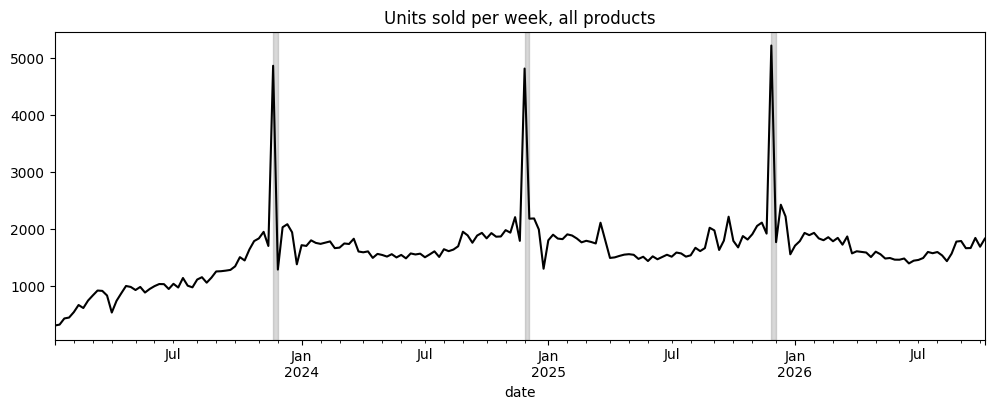

In [6]:
weekly = sales.set_index("date").units_sold.resample("W").sum()

ax = weekly.iloc[1:].plot(figsize=(12, 4), color="black", title="Units sold per week, all products")
for year in [2023, 2024, 2025]:
    ax.axvspan(bw_days[year][0], bw_days[year][-1], color="grey", alpha=0.3)
plt.show()

The grey bands are Black Week. Every year, sales jump. (We left out the very first week, because it only has one day.)

In [7]:
for year in [2023, 2024, 2025]:
    units = sales[sales.date.isin(bw_days[year])].units_sold.sum()
    print(year, f"{units:,} units in Black Week")

2023 5,385 units in Black Week
2024 5,491 units in Black Week
2025 5,892 units in Black Week


## 3. Two traps in the data

Before we build anything, we look for things that could fool the model.

### Trap 1: Zero sales because the shelf was empty

When a product sells out, sales drop to zero until new stock arrives. That zero doesn't mean nobody wanted it. It means **there was nothing to sell**.

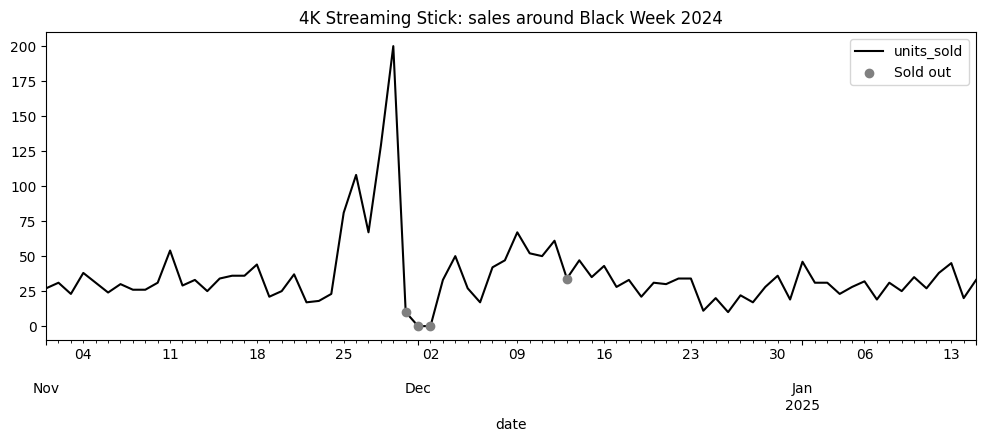

In [8]:
one = sales[sales.sku == "SKU015"].set_index("date").loc["2024-11-01":"2025-01-15"]
empty = one[one.stockout_flag == 1]

ax = one.units_sold.plot(figsize=(12, 4), color="black", title="4K Streaming Stick: sales around Black Week 2024")
ax.scatter(empty.index, empty.units_sold, color="grey", zorder=3, label="Sold out")
ax.legend()
plt.show()

In [9]:
for year in [2023, 2024, 2025]:
    week = sales[sales.date.isin(bw_days[year])]
    n = week.groupby("sku").stockout_flag.max().sum()
    print(year, n, "products sold out during Black Week")

2023 9 products sold out during Black Week
2024 11 products sold out during Black Week
2025 13 products sold out during Black Week


**Why it's a problem:** if the model learns from these zeros, it thinks demand was low and forecasts too little.

**What we do:** we remove sold-out days before the model learns. Prophet copes with missing days without problems.

This is **cleaning the data**, not a regressor. It comes first.

### Trap 2: The discount changes every year

The same product can have a different Black Week discount each year:

In [10]:
bw_discount = {}
for year in [2023, 2024, 2025]:
    week = sales[sales.date.isin(bw_days[year])]
    bw_discount[year] = week.groupby("sku").discount_pct.max() * 100

bw_discount = pd.DataFrame(bw_discount).round(0)
bw_discount.loc[["SKU026", "SKU036", "SKU028"]]

,2023,2024,2025
sku,,,
SKU026,25.0,20.0,0.0
SKU036,0.0,0.0,20.0
SKU028,5.0,20.0,20.0


For example, one product had 25% off in 2023 and **no discount at all** in 2025.

**Why it's a problem:** "same as last year" quietly assumes the same discount as last year. If the discount changes, so will sales.

**What we do:** we give the model the discount as a regressor.

## 4. Choose the products

A model can only learn a Black Week effect if it has seen Black Weeks. We keep products that:
- were on sale during **all three** past Black Weeks (3 × 8 = 24 days), and
- are **still on sale** today.

In [11]:
past_days = bw_days[2023].append(bw_days[2024]).append(bw_days[2025])
days_on_sale = sales[sales.date.isin(past_days)].groupby("sku").date.nunique()
full_history = days_on_sale[days_on_sale == 24].index

scope = products[products.sku.isin(full_history) & products.end_of_life_date.isna()]
print(len(scope), "products to forecast")
scope[["sku", "product_name", "category"]]

21 products to forecast


,sku,product_name,category
5,SKU006,Portable Bluetooth Speaker,Audio
10,SKU011,Fitness Band,Wearables
14,SKU015,4K Streaming Stick,TV & Smart Home
19,SKU020,Video Doorbell,TV & Smart Home
20,SKU021,Indoor Security Camera,TV & Smart Home
21,SKU022,Smart Plug 2-Pack,TV & Smart Home
22,SKU023,Wireless Game Controller,Gaming
25,SKU026,Mechanical Keyboard,Gaming
26,SKU027,Gaming Mouse,Gaming
27,SKU028,E-Reader,Computing & Mobile


Newer products don't have enough history for this approach. They would need a different method.

## 5. Prepare the regressors

### Events: Black Week and other promotions

Prophet wants a table with:
- `holiday`: the name of the event
- `ds`: the day it starts
- `upper_window`: how many more days it lasts

We make two tables: one with **only Black Week**, and one with **all promotions**. That way we can test them separately.

In [12]:
all_events = pd.DataFrame({
    "holiday": np.where(calendar.event == "Black Week", "black_week", "other_promotion"),
    "ds": calendar.start_date,
    "lower_window": 0,
    "upper_window": (calendar.end_date - calendar.start_date).dt.days,
})

black_week_only = all_events[all_events.holiday == "black_week"]
black_week_only

,holiday,ds,lower_window,upper_window
4,black_week,2023-11-20,0,7
10,black_week,2024-11-25,0,7
16,black_week,2025-11-24,0,7
22,black_week,2026-11-23,0,7


Because Black Week has a window of 8 days, Prophet learns a **separate effect for each day**. That way, Black Friday and Cyber Monday can be bigger than Tuesday.

### Number: the discount

The discount is already in the sales data (`discount_pct`), for every product and every day. Nothing to prepare for the past. For the future, we use the promotion plan (section 8).

### A recipe for one forecast

We'll make many forecasts with different regressors. To avoid writing the same lines again and again, we put them in a **recipe** (a function). You give it:
- `train`: the sales the model may learn from
- `df`: all sales of the product (for the discounts)
- `year`: which Black Week to forecast
- `events`: which events to use (or none)
- `discount`: whether to use the discount (True or False)

It gives back the forecast for that year's Black Week, day by day.

In [13]:
def forecast_black_week(train, df, year, events=None, discount=False):
    model = Prophet(holidays=events)
    columns = ["ds", "y"]
    if discount:
        model.add_regressor("discount_pct")
        columns.append("discount_pct")
    model.fit(train[columns])

    future = model.make_future_dataframe(periods=81)
    if discount:
        future = future.merge(df[["ds", "discount_pct"]], on="ds", how="left")
        future["discount_pct"] = future.discount_pct.fillna(0)

    forecast = model.predict(future)
    forecast["yhat"] = forecast.yhat.clip(lower=0)   # no negative sales
    return forecast[forecast.ds.isin(bw_days[year])]

## 6. The test: what is each regressor worth?

We go back in time. We pretend it's **12 October**, forecast that year's Black Week, and compare with what really sold. We do this for **2024 and 2025**, because one year could be luck.

We test five versions, each knowing one thing more:

| Step | What the model knows |
|---|---|
| 0 | Past sales only |
| 1 | + sold-out days removed |
| 2 | + Black Week as an event |
| 3 | + other promotions as events |
| 4 | + the discount |

And the simple method a planner would use: **same as last year**.

⏳ This makes 210 forecasts, so it takes a minute.

In [14]:
results = []

for year in [2024, 2025]:
    cutoff = pd.Timestamp(f"{year}-10-12")

    for sku in scope.sku:
        df = sales[sales.sku == sku].rename(columns={"date": "ds", "units_sold": "y"})
        past = df[df.ds < cutoff]
        clean = past[past.stockout_flag == 0]

        step0 = forecast_black_week(past, df, year)
        step1 = forecast_black_week(clean, df, year)
        step2 = forecast_black_week(clean, df, year, events=black_week_only)
        step3 = forecast_black_week(clean, df, year, events=all_events)
        step4 = forecast_black_week(clean, df, year, events=all_events, discount=True)

        last_year = df[df.ds.isin(bw_days[year - 1])]
        actual = df[df.ds.isin(bw_days[year])]

        results.append([
            year, sku,
            last_year.y.sum(),
            step0.yhat.sum(), step1.yhat.sum(), step2.yhat.sum(), step3.yhat.sum(), step4.yhat.sum(),
            actual.y.sum(),
            actual.stockout_flag.sum(),
        ])

test = pd.DataFrame(results, columns=[
    "year", "sku", "last_year",
    "step0", "step1", "step2", "step3", "step4",
    "actual", "sold_out_days",
])
test.head()

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,year,sku,last_year,step0,step1,step2,step3,step4,actual,sold_out_days
0,2024,SKU006,296,62.251744,69.783030,283.050786,282.591439,284.002167,448,0
1,2024,SKU011,256,73.240695,70.544092,188.261668,183.833969,188.733826,230,3
2,2024,SKU015,776,191.967264,204.403021,789.642244,783.651551,866.571262,595,3
3,2024,SKU020,73,33.478516,33.478516,66.998212,65.919357,64.250720,71,0
4,2024,SKU021,140,48.430684,48.806319,127.064248,127.597069,129.276074,90,1


### A fair comparison

Some products sold out **during** the test week. Their "actual" sales are too low, so a good forecast would wrongly look too high. We only compare on products that **did not sell out** in the test week.

In [15]:
fair = test[test.sold_out_days == 0]
print(len(fair[fair.year == 2024]), "products in 2024,", len(fair[fair.year == 2025]), "products in 2025")

16 products in 2024, 16 products in 2025


### How we measure the error

For each product: how many units was the forecast off, too high or too low? We add that up for all products and divide by the total actual sales. This is called **WAPE**.

**Example:** we forecast 100 and 50, actual was 90 and 60. Misses: 10 + 10 = 20 units. Total actual: 150. Error: 20 / 150 = **13%**.

Lower is better.

In [16]:
methods = ["last_year", "step0", "step1", "step2", "step3", "step4"]
names = {
    "last_year": "Same as last year",
    "step0": "0. Past sales only",
    "step1": "1. + sold-out days removed",
    "step2": "2. + Black Week event",
    "step3": "3. + other promotions",
    "step4": "4. + discount",
}

errors = pd.DataFrame(index=[names[m] for m in methods])
for year in [2024, 2025]:
    t = fair[fair.year == year]
    errors[year] = [round(abs(t[m] - t.actual).sum() / t.actual.sum() * 100) for m in methods]

errors

,2024,2025
Same as last year,22,11
0. Past sales only,63,34
1. + sold-out days removed,62,28
2. + Black Week event,22,12
3. + other promotions,22,12
4. + discount,15,12


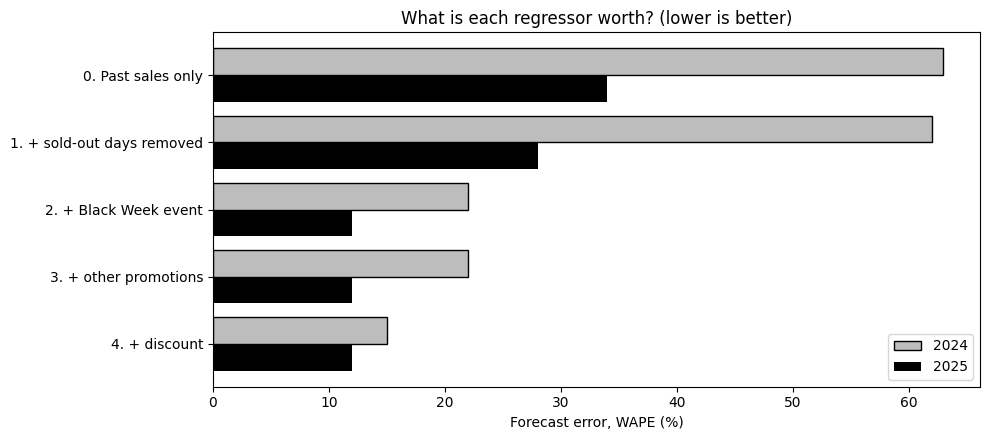

In [17]:
steps = errors.drop("Same as last year").iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(steps))
ax.barh(y + 0.2, steps[2024], height=0.4, color="#BDBDBD", edgecolor="black", label="2024")
ax.barh(y - 0.2, steps[2025], height=0.4, color="black", label="2025")
ax.set_yticks(y)
ax.set_yticklabels(steps.index)
ax.set_xlabel("Forecast error, WAPE (%)")
ax.set_title("What is each regressor worth? (lower is better)")
ax.legend()
plt.tight_layout()
plt.savefig("../outputs/chart_regressor_steps.png", dpi=150)
plt.show()

### What we learn

1. **Past sales alone are not enough.** The model misses a big part of Black Week, because nothing in the sales history says *"this week is special"*.
2. **Removing sold-out days helps a bit**, but doesn't solve the main problem.
3. **The Black Week event is the big step.** Now the model knows when Black Week is, and it becomes as good as "same as last year".
4. **Other promotions add almost nothing** for this question. Not every regressor earns its place, which is why we test each one.
5. **The discount helps when it changes.** In 2024 it clearly lowered the error. In 2025, it made little difference.

## 7. The decision

"Same as last year" and the model with all regressors (step 4) make **different mistakes**. Last year copies last year's luck. The model learns from all years, but has seen few Black Weeks.

So we try one more thing: **the average of both.**

In [18]:
fair = fair.copy()
fair["combined"] = (fair.last_year + fair.step4) / 2

for year in [2024, 2025]:
    t = fair[fair.year == year]
    for m in ["last_year", "step4", "combined"]:
        error = abs(t[m] - t.actual).sum() / t.actual.sum() * 100
        print(year, f"{m:10}", f"{error:.0f}%")

2024 last_year  22%
2024 step4      15%
2024 combined   18%
2025 last_year  11%
2025 step4      12%
2025 combined   8%


The combined forecast is the **most reliable over both years**: never the worst, and clearly the best in 2025.

**Our choice:** the average of
- **same as last year** (the planner's view), and
- **Prophet with Black Week, other promotions and the planned discount** (the model's view).

### How sure are we? A planning range

One number is not enough to plan stock. So we look at how far off the combined forecast was in the test. We divide actual sales by the forecast, for every product:
- 1.00 means perfect,
- 0.80 means actual was 20% lower,
- 1.20 means actual was 20% higher.

In 8 out of 10 cases, the result was between these two numbers:

In [19]:
ratio = fair.actual / fair.combined
low_factor, high_factor = np.percentile(ratio, [10, 90])

print(f"Low factor:  {low_factor:.2f}")
print(f"High factor: {high_factor:.2f}")

Low factor:  0.71
High factor: 1.19


For 2026: **low = forecast × low factor**, and **high = forecast × high factor**.

## 8. Forecast Black Week 2026

Same recipe, now with all sales up to **12 October 2026**.

One difference: for the future, the discounts come from **marketing's promotion plan**.

In [20]:
promo_plan[promo_plan.event == "Black Week"].head()

,event,sku,start_date,end_date,discount_pct
15,Black Week,SKU003,2026-11-23,2026-11-30,0.10
16,Black Week,SKU005,2026-11-23,2026-11-30,0.15
17,Black Week,SKU006,2026-11-23,2026-11-30,0.35
18,Black Week,SKU007,2026-11-23,2026-11-30,0.25
19,Black Week,SKU010,2026-11-23,2026-11-30,0.30


In [21]:
cutoff = pd.Timestamp("2026-10-12")
plan = []
daily = []

for sku in scope.sku:
    df = sales[sales.sku == sku].rename(columns={"date": "ds", "units_sold": "y"})

    # add the planned 2026 discounts for this product
    future_days = pd.DataFrame({"ds": pd.date_range(cutoff, "2026-12-31")})
    future_days["discount_pct"] = 0.0
    for row in promo_plan[promo_plan.sku == sku].itertuples():
        future_days.loc[future_days.ds.between(row.start_date, row.end_date), "discount_pct"] = row.discount_pct
    df_with_plan = pd.concat([df[["ds", "discount_pct"]], future_days])

    clean = df[(df.ds < cutoff) & (df.stockout_flag == 0)]
    forecast = forecast_black_week(clean, df_with_plan, 2026, events=all_events, discount=True)

    last_year = df[df.ds.isin(bw_days[2025])]
    plan.append([
        sku,
        last_year.y.sum(),
        forecast.yhat.sum(),
        last_year.stockout_flag.sum() > 0,
        last_year.discount_pct.max() * 100,
        future_days[future_days.ds.isin(bw_days[2026])].discount_pct.max() * 100,
    ])
    daily.append(forecast.assign(sku=sku)[["sku", "ds", "yhat"]])

plan = pd.DataFrame(plan, columns=["sku", "last_year", "model", "sold_out_last_year", "discount_2025", "discount_2026"])
plan["forecast"] = (plan.last_year + plan.model) / 2
plan["low"] = plan.forecast * low_factor
plan["high"] = plan.forecast * high_factor
plan.head()

,sku,last_year,model,sold_out_last_year,discount_2025,discount_2026,forecast,low,high
0,SKU006,456,442.804929,False,30.0,35.0,449.402465,321.195408,534.226286
1,SKU011,260,344.365093,True,30.0,20.0,302.182546,215.974886,359.218901
2,SKU015,657,876.396312,True,25.0,30.0,766.698156,547.971910,911.410907
3,SKU020,63,71.234803,False,10.0,0.0,67.117401,47.969922,79.785677
4,SKU021,108,100.752702,False,15.0,0.0,104.376351,74.599512,124.077180


### Notes for the planning team

We add a note to products that need extra attention:
- **Sold out last year:** last year's sales were limited by stock, so real demand was higher. Plan towards the high end.
- **Bigger discount than last year:** expect more sales than last year.
- **Smaller discount than last year:** expect fewer sales than last year.

In [22]:
plan["note"] = ""
plan.loc[plan.discount_2026 > plan.discount_2025, "note"] = "Bigger discount than last year"
plan.loc[plan.discount_2026 < plan.discount_2025, "note"] = "Smaller discount than last year"
plan.loc[plan.sold_out_last_year, "note"] = plan.note + "; Sold out last year: plan towards the high end"
plan["note"] = plan.note.str.strip("; ")

print(plan.sold_out_last_year.sum(), "products sold out last year")
print((plan.discount_2026 != plan.discount_2025).sum(), "products with a different discount than last year")

5 products sold out last year
15 products with a different discount than last year


## 9. The deliverable for the client

### Black Week 2026 demand plan, per product

In [23]:
deliverable = plan.merge(products[["sku", "product_name", "category"]], on="sku")
deliverable = deliverable[["product_name", "category", "forecast", "low", "high",
                           "last_year", "discount_2025", "discount_2026", "note"]]
deliverable[["forecast", "low", "high"]] = deliverable[["forecast", "low", "high"]].round(0).astype(int)
deliverable = deliverable.sort_values("forecast", ascending=False)

deliverable.to_csv("../outputs/black_week_2026_demand_plan.csv", index=False)
deliverable

,product_name,category,forecast,low,high,last_year,discount_2025,discount_2026,note
2,4K Streaming Stick,TV & Smart Home,767,548,911,657,25.0,30.0,Bigger discount than last year; Sold out last ...
0,Portable Bluetooth Speaker,Audio,449,321,534,456,30.0,35.0,Bigger discount than last year
5,Smart Plug 2-Pack,TV & Smart Home,413,295,491,348,25.0,25.0,Sold out last year: plan towards the high end
6,Wireless Game Controller,Gaming,310,222,369,261,25.0,35.0,Bigger discount than last year; Sold out last ...
1,Fitness Band,Wearables,302,216,359,260,30.0,20.0,Smaller discount than last year; Sold out last...
11,USB-C Cable 2m,Computing & Mobile,262,187,311,258,25.0,20.0,Smaller discount than last year
9,E-Reader,Computing & Mobile,261,187,311,243,20.0,15.0,Smaller discount than last year; Sold out last...
10,USB-C Charger 65W,Computing & Mobile,179,128,213,171,15.0,20.0,Bigger discount than last year
13,Universal Phone Case,Computing & Mobile,167,120,199,154,15.0,25.0,Bigger discount than last year
12,"Power Bank 20,000 mAh",Computing & Mobile,125,89,149,126,20.0,10.0,Smaller discount than last year


In [24]:
total = deliverable[["forecast", "low", "high", "last_year"]].sum()

print(f"Black Week 2026, {len(deliverable)} products")
print(f"  Forecast:       {total.forecast:,.0f} units")
print(f"  Planning range: {total.low:,.0f} to {total.high:,.0f} units")
print(f"  Last year:      {total.last_year:,.0f} units")

Black Week 2026, 21 products
  Forecast:       3,793 units
  Planning range: 2,713 to 4,511 units
  Last year:      3,510 units


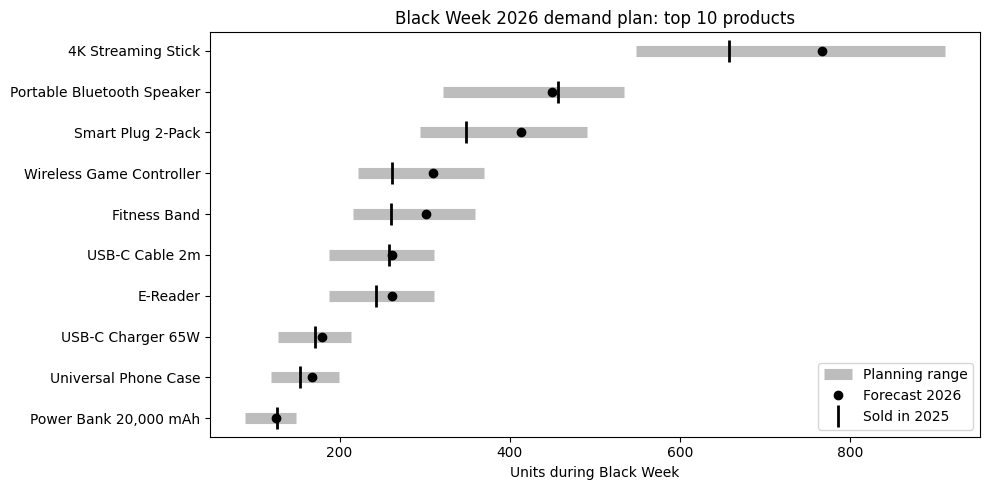

In [25]:
top = deliverable.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.hlines(top.product_name, top.low, top.high, color="#BDBDBD", lw=8, label="Planning range")
ax.plot(top.forecast, top.product_name, "o", color="black", label="Forecast 2026")
ax.plot(top.last_year, top.product_name, "|", color="black", ms=16, mew=2, label="Sold in 2025")
ax.set_xlabel("Units during Black Week")
ax.set_title("Black Week 2026 demand plan: top 10 products")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../outputs/chart_demand_plan_top10.png", dpi=150)
plt.show()

### Which days will be busiest?

For warehouse staff and customer service, it helps to know the busiest days. We take the model's day-by-day shape and scale it to the combined forecast.

This is a **guide**, not an exact plan: how sales split between Friday, Saturday and Cyber Monday can shift from year to year.

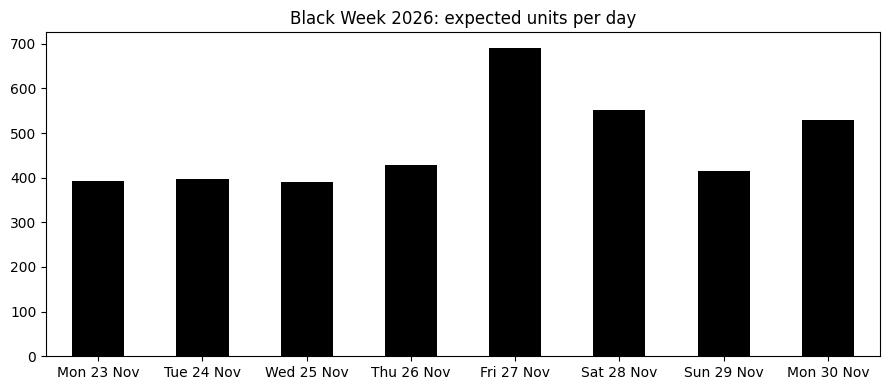

In [26]:
daily = pd.concat(daily)
daily["share"] = daily.yhat / daily.groupby("sku").yhat.transform("sum")
daily = daily.merge(plan[["sku", "forecast"]], on="sku")
daily["units"] = daily.share * daily.forecast

per_day = daily.groupby("ds").units.sum().round(0)
per_day.index = per_day.index.strftime("%a %d %b")
per_day.to_csv("../outputs/black_week_2026_daily_profile.csv")

ax = per_day.plot(kind="bar", figsize=(9, 4), color="black", rot=0, title="Black Week 2026: expected units per day")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig("../outputs/chart_daily_profile.png", dpi=150)
plt.show()

## 10. Limitations

- **Synthetic data.** The patterns are realistic, but they're not real market data.
- **Few Black Weeks to learn from.** At most three per product, and only one before the 2024 test.
- **The discount effect is learned from the past.** A much deeper discount than ever before (say 50%) would be a guess.
- **Promotions in the calendar are for the whole shop.** Not every product joins every promotion.
- **Sold-out days are removed, not estimated.** Estimating how much would have sold is a natural next step.
- **Established products only.** New products need another approach, for example using the sales history of the model they replace.

## Summary

| | |
|---|---|
| **Question** | How many units will each product sell in Black Week 2026? |
| **Key insight** | A forecast needs to know what makes a week special: the event and the discount |
| **Method** | Average of "same as last year" and Prophet with Black Week, promotions and planned discount |
| **Tested on** | Black Week 2024 and 2025 |
| **Deliverable** | Forecast, planning range and notes per product, plus the busiest days |